# Figure S16A — disorder in human transcription factors

Main panel: every human transcription factor (Lambert *et al.* (2018) *Cell* 172, 650–665) as a horizontal bar of its length, split into residues inside predicted IDRs (red) and outside them (black), ordered by length. Inset: fraction of each protein inside IDRs for the human proteome (black) and the transcription factors (blue), with the median marked.

**How it is made.** IDRs come from `HP_IDRs.tsv` and `TF_IDRs.tsv` in `data/human_transcription_factors/` (shared data directory), written by `build_idr_tables.py` (metapredict 3.1.0, V3, default domain decomposition); sequences from the UniProt FASTA files in the same directory.

**Outputs:** `figures/figure_S16A.pdf` (bars) and `figures/figure_S16A_inset.pdf` (inset)

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from figtools import apply_style, require_metapredict_3_1, save_panel
from tf_idrs import idr_residue_counts, load_set

require_metapredict_3_1()
apply_style()
%matplotlib inline
%config InlineBackend.figure_format = 'retina'

DISORDER_COLOR, FOLDED_COLOR = 'red', 'black'
PROTEOME_COLOR, TF_COLOR = 'black', 'blue'
# seed for the horizontal jitter of points in the inset
JITTER_SEED = 2024

TFs, TF_idrs = load_set('tfs')
HP, HP_idrs = load_set('proteome')
print(f'Human proteome: {len(HP)} proteins, {sum(map(len, HP_idrs.values()))} IDRs')
print(f'Human TFs: {len(TFs)} proteins, {sum(map(len, TF_idrs.values()))} IDRs')

metapredict 3.1.0+6.ga1b28a7.dirty from /Users/alex/Dropbox/WASHU/Holehouse/tools/metapredict/metapredict/metapredict (git 7dcf52c)
Human proteome: 20656 proteins, 33713 IDRs
Human TFs: 1627 proteins, 3526 IDRs


In [2]:
# per-protein IDR residues, folded residues and fraction disordered
tf_disordered = idr_residue_counts(TFs, TF_idrs)
fraction_disordered = [tf_disordered[acc] / len(seq) for acc, seq in TFs.items()]
hp_disordered = idr_residue_counts(HP, HP_idrs)
fraction_disordered_HP = [hp_disordered[acc] / len(seq) for acc, seq in HP.items()]

# longest protein first
sorted_lists = sorted(((len(seq), tf_disordered[acc], len(seq) - tf_disordered[acc]) for acc, seq in TFs.items()),
                      reverse=True)
prot_len, number_disordered, number_ordered = (list(x) for x in zip(*sorted_lists))

print(f'median fraction disordered: proteome {np.median(fraction_disordered_HP):.3f}, '
      f'TFs {np.median(fraction_disordered):.3f}')

median fraction disordered: proteome 0.236, TFs 0.569


Wrote figures/figure_S16A.pdf


PosixPath('figures/figure_S16A.pdf')

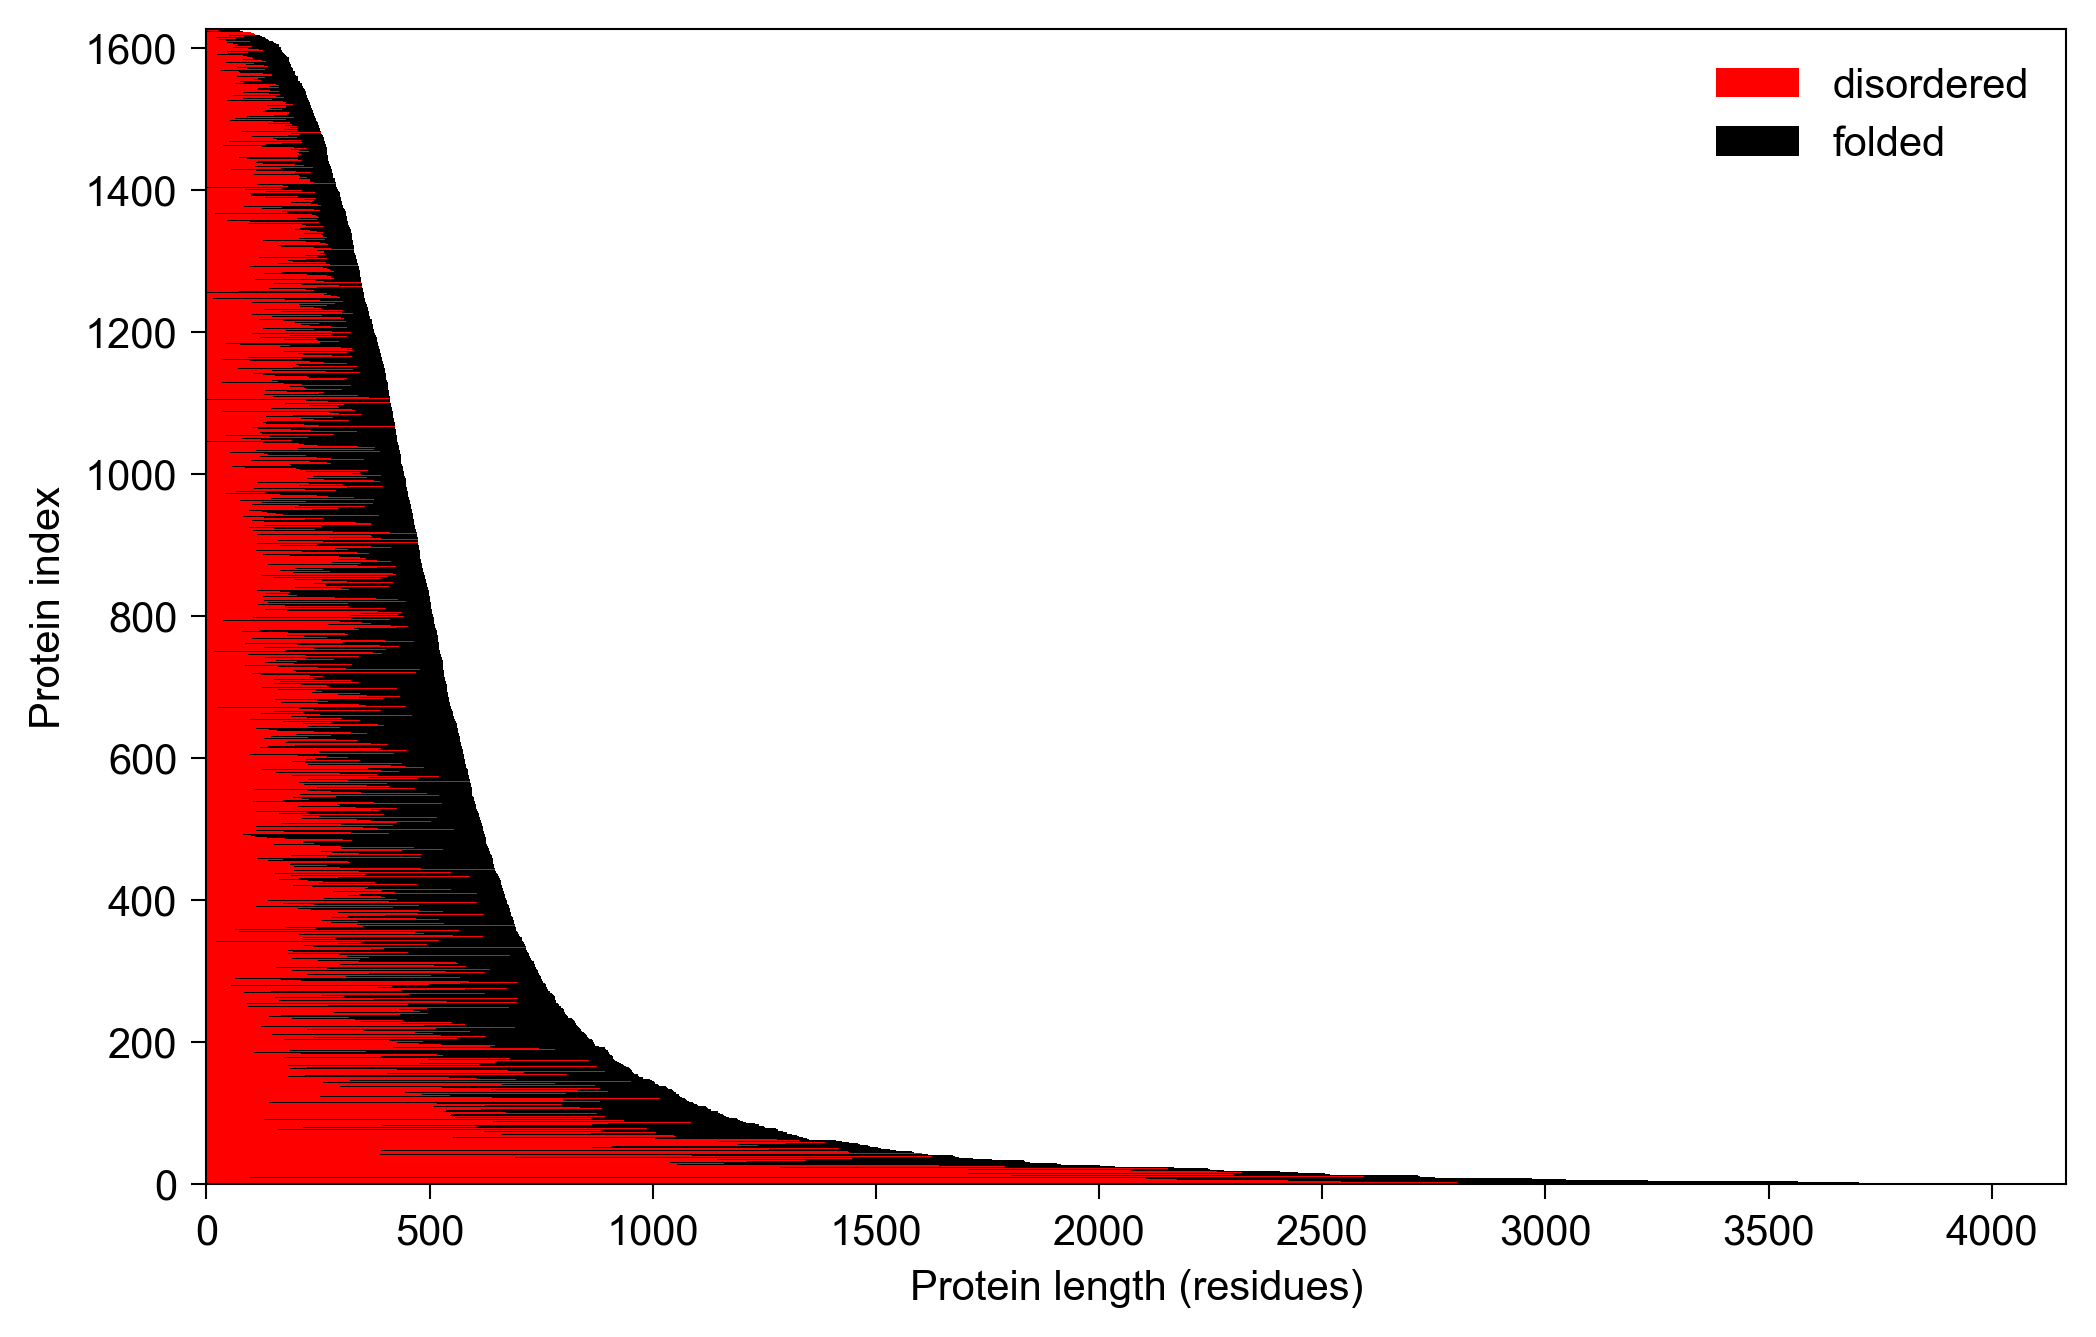

In [3]:
fig, ax = plt.subplots(figsize=(8, 5), dpi=150)
x = np.arange(len(prot_len))
ax.barh(x, number_disordered, label='disordered', color=DISORDER_COLOR, height=1)
ax.barh(x, number_ordered, left=number_disordered, label='folded', color=FOLDED_COLOR, height=1)
ax.set_xlabel('Protein length (residues)')
ax.set_ylabel('Protein index')
ax.set_ylim([x[0], x[-1]])
ax.legend()
save_panel(fig, 'figure_S16A')

Wrote figures/figure_S16A_inset.pdf


PosixPath('figures/figure_S16A_inset.pdf')

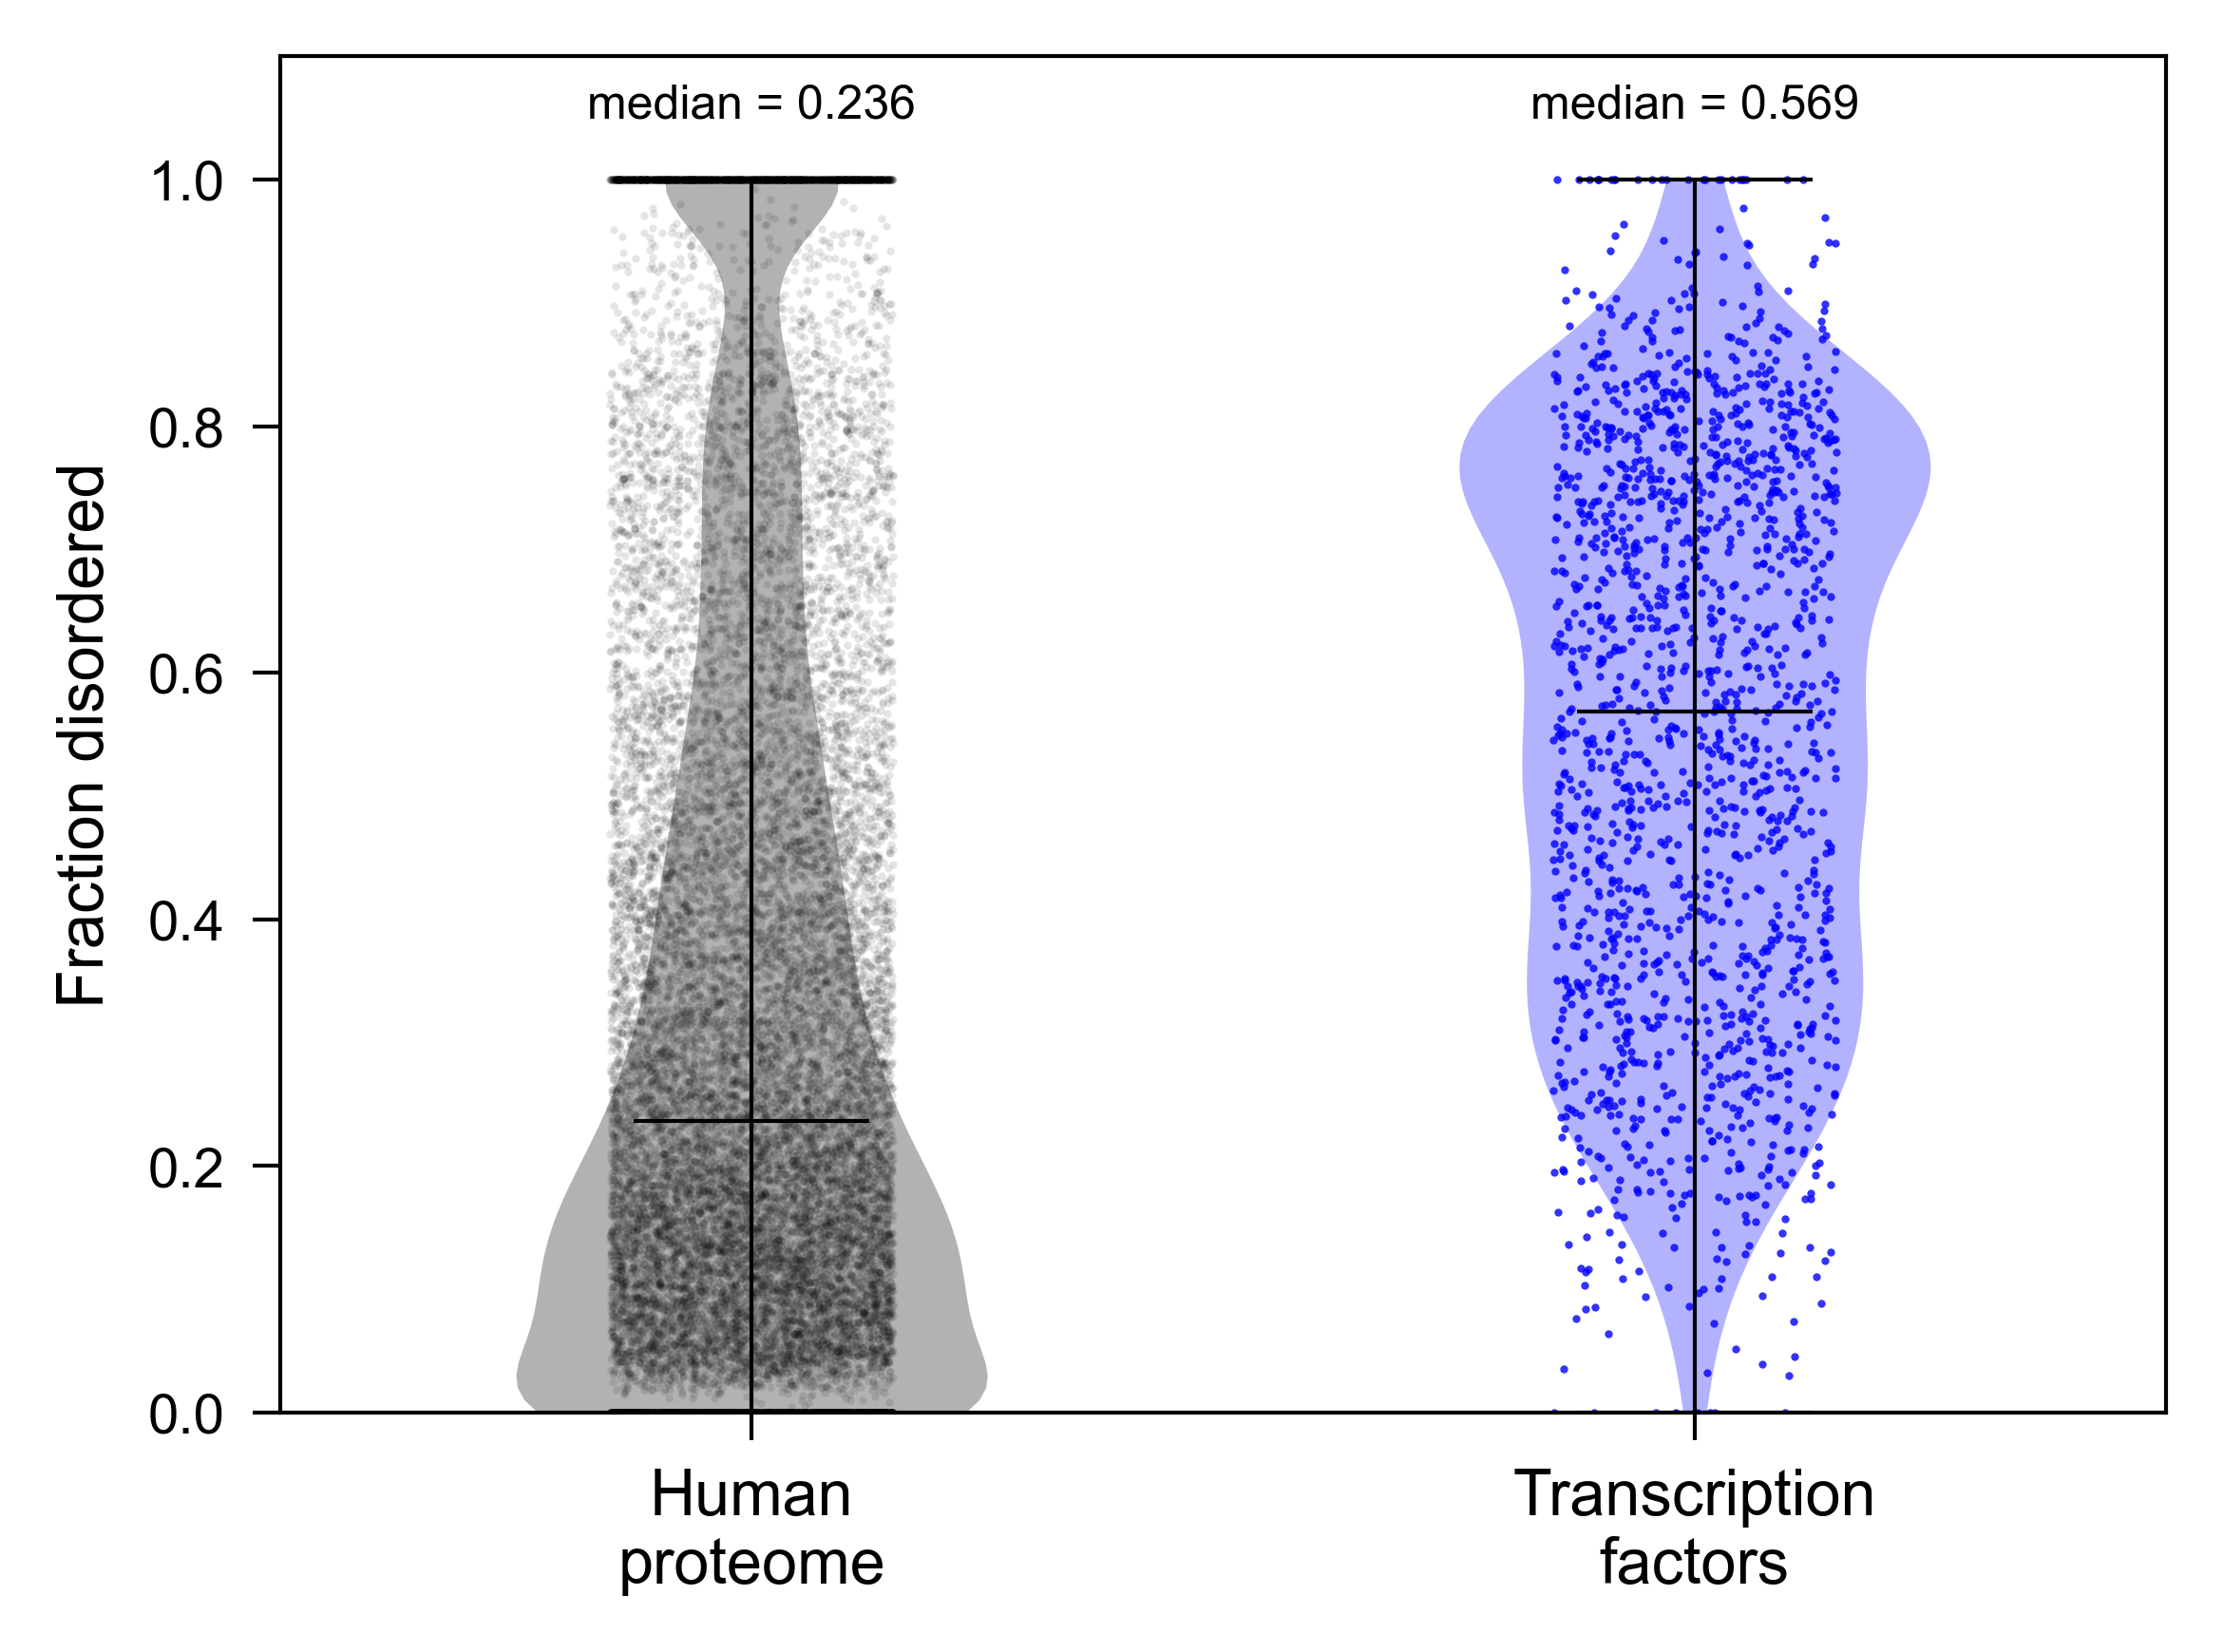

In [4]:
# inset: jittered points + violins, human proteome vs TFs
rng = np.random.default_rng(JITTER_SEED)
fig, ax = plt.subplots(figsize=(4, 3), dpi=300)
for position, values, color, alpha in [(1, fraction_disordered_HP, PROTEOME_COLOR, 0.1),
                                       (2, fraction_disordered, TF_COLOR, 0.8)]:
    jitter = (rng.random(len(values)) - 0.5) * 0.3
    ax.plot(position + jitter, values, '.', color=color, alpha=alpha, ms=2, mew=0)
    ax.text(position, 1.05, f'median = {np.median(values):.3f}', fontsize=6, ha='center')

parts = ax.violinplot([fraction_disordered_HP, fraction_disordered], showmedians=True)
for body, color in zip(parts['bodies'], [PROTEOME_COLOR, TF_COLOR]):
    body.set_color(color)
    body.set_linewidth(0)
for partname in ('cbars', 'cmins', 'cmaxes', 'cmedians'):
    parts[partname].set_color('k')
    parts[partname].set_linewidth(0.5)

ax.set_xlim([0.5, 2.5])
ax.set_ylim([0, 1.1])
ax.set_xticks([1, 2], ['Human\nproteome', 'Transcription\nfactors'], fontsize=8)
ax.tick_params(axis='y', labelsize=7)
ax.set_ylabel('Fraction disordered', fontsize=8)
plt.tight_layout()
save_panel(fig, 'figure_S16A_inset')